# 01 Explore the data
What does the Eedi Task 3/4 data look like before we build any model?

In [1]:
import sys
sys.path.append("..")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import load_data

FIG = Path("../results/figures")   # figures for the report
FIG.mkdir(parents=True, exist_ok=True)

df = load_data()
df.shape

(1382727, 19)

## 1. Dataset at a glance
How big is the data, and what time period does it cover?

In [2]:
print("Answers:  ", f"{len(df):,}")
print("Students: ", f"{df['UserId'].nunique():,}")
print("Questions:", f"{df['QuestionId'].nunique():,}")
print("From", df["DateAnswered"].min().date(), "to", df["DateAnswered"].max().date())
print("Columns:  ", df.shape[1])
print(list(df.columns))

Answers:   1,382,727
Students:  4,918
Questions: 948
From 2019-09-06 to 2020-05-01
Columns:   19
['QuestionId', 'UserId', 'AnswerId', 'IsCorrect', 'CorrectAnswer', 'AnswerValue', 'DateAnswered', 'Confidence', 'GroupId', 'QuizId', 'SchemeOfWorkId', 'Gender', 'DateOfBirth', 'PremiumPupil', 'SubjectId', 'skill_L0', 'skill_L1', 'skill_L2', 'skill_L3']


**Takeaway:** The data has 1.38 million answers from 4,918 students on 948 maths questions. The answers come from one school year (September 2019 to May 2020). After merging, the table has 19 columns.

## 2. Data quality
Are there duplicates, and can we trust the target?

In [3]:
print("Duplicate answers:", df["AnswerId"].duplicated().sum())
print("Student answered same question twice:", df.duplicated(subset=["UserId", "QuestionId"]).sum())
right_option = df["CorrectAnswer"] == df["AnswerValue"]
print("IsCorrect mismatches:", (right_option != df["IsCorrect"]).sum())

Duplicate answers: 0
Student answered same question twice: 0
IsCorrect mismatches: 0


**Takeaway:** The data is clean. No answer appears twice, and no student answers the same question twice. `IsCorrect` always matches the student's choice, so we can trust it.

## 3. Target: IsCorrect
How balanced are correct and incorrect answers?

In [4]:
print("Percent correct:", round(df["IsCorrect"].mean() * 100, 1))

Percent correct: 53.7


**Takeaway:** 53.7% of answers are correct, so right and wrong answers are almost equal in number. A model that always says "correct" gets 53.7% right. Our models must do better than this.

## 4. Student confidence
How many answers have a rating, and are students as correct as they think?

### 4a. Who rates, and how often?

=== 1. Who rates their confidence? ===
Students in total:               4,918
Students who rated at least once: 4,284 (87%)
Students who never rated:         634 (13%)

=== 2. How often does each student rate? (% of their own answers) ===
Typical student (median): 9.5%
Average student (mean):   26.3%
Rate under 2% of answers: 26% of students
Rate over 40% of answers: 26% of students
Rate every answer:        29 students

Full summary:
students    4918.0
mean          26.3
std           32.4
min            0.0
25%            1.8
50%            9.5
75%           42.5
max          100.0
Name: Confidence, dtype: float64

=== 3. Each student's most common rating ===
Usually says   0%:   556 students (13%)
Usually says  25%:   127 students (3%)
Usually says  50%:   516 students (12%)
Usually says  75%:   873 students (20%)
Usually says 100%: 2,212 students (52%)



The 20% of students who rate the most give 73.2% of all ratings


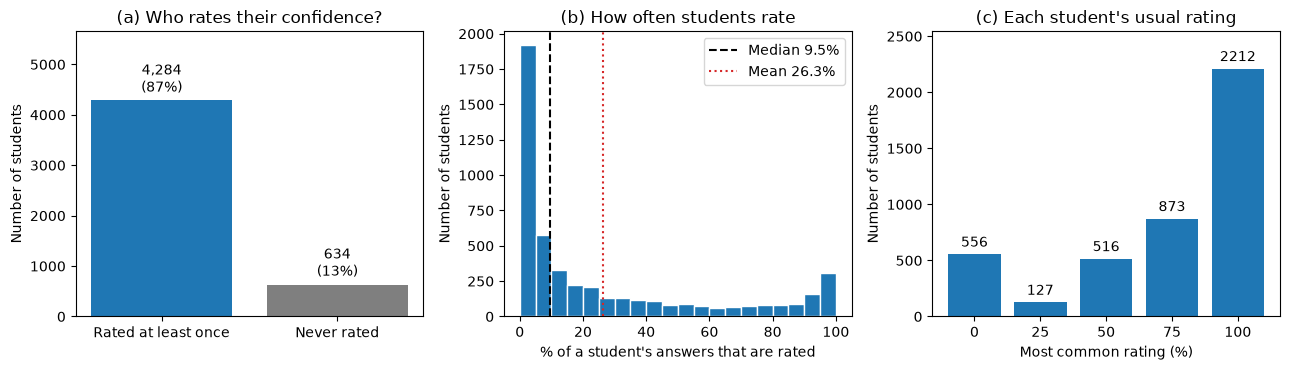

In [5]:
rated = df[df["Confidence"].notna()]
n_students = df["UserId"].nunique()
n_raters = rated["UserId"].nunique()

# 1. How many students ever give a rating?
print("=== 1. Who rates their confidence? ===")
print(f"Students in total:               {n_students:,}")
print(f"Students who rated at least once: {n_raters:,} ({n_raters / n_students:.0%})")
print(f"Students who never rated:         {n_students - n_raters:,} ({(n_students - n_raters) / n_students:.0%})")

# 2. How often does each student rate?
rate_share = df.groupby("UserId")["Confidence"].apply(lambda c: c.notna().mean() * 100)
print("\n=== 2. How often does each student rate? (% of their own answers) ===")
print(f"Typical student (median): {rate_share.median():.1f}%")
print(f"Average student (mean):   {rate_share.mean():.1f}%")
print(f"Rate under 2% of answers: {(rate_share < 2).mean():.0%} of students")
print(f"Rate over 40% of answers: {(rate_share > 40).mean():.0%} of students")
print(f"Rate every answer:        {(rate_share == 100).sum():,} students")
print("\nFull summary:")
print(rate_share.describe().round(1).rename({"count": "students"}))

# 3. Each student's usual rating
favourite = rated.groupby("UserId")["Confidence"].agg(lambda c: c.mode().iloc[0])
fav_counts = favourite.value_counts().sort_index()
print("\n=== 3. Each student's most common rating ===")
for rating, count in fav_counts.items():
    print(f"Usually says {int(rating):>3}%: {count:>5,} students ({count / n_raters:.0%})")

# 4. How much of all ratings comes from the 20% of students who rate the most?
n_ratings = rated.groupby("UserId").size().reindex(df["UserId"].unique(), fill_value=0).sort_values(ascending=False)
top20 = n_ratings.head(int(len(n_ratings) * 0.2)).sum() / n_ratings.sum() * 100
print(f"\nThe 20% of students who rate the most give {top20:.1f}% of all ratings")

# ---------- Figure ----------
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

ax = axes[0]
bars = ax.bar(["Rated at least once", "Never rated"],
              [n_raters, n_students - n_raters], color=["tab:blue", "tab:gray"])
ax.bar_label(bars, labels=[f"{n_raters:,}\n({n_raters / n_students:.0%})",
                           f"{n_students - n_raters:,}\n({(n_students - n_raters) / n_students:.0%})"], padding=3)
ax.set_ylabel("Number of students")
ax.set_title("(a) Who rates their confidence?")
ax.set_ylim(0, n_students * 1.15)

ax = axes[1]
ax.hist(rate_share, bins=20, range=(0, 100), edgecolor="white")
ax.axvline(rate_share.median(), color="black", linestyle="--", label=f"Median {rate_share.median():.1f}%")
ax.axvline(rate_share.mean(), color="tab:red", linestyle=":", label=f"Mean {rate_share.mean():.1f}%")
ax.set_xlabel("% of a student's answers that are rated")
ax.set_ylabel("Number of students")
ax.set_title("(b) How often students rate")
ax.legend()

ax = axes[2]
bars = ax.bar([str(int(v)) for v in fav_counts.index], fav_counts.values, color="tab:blue")
ax.bar_label(bars, padding=3)
ax.set_xlabel("Most common rating (%)")
ax.set_ylabel("Number of students")
ax.set_title("(c) Each student's usual rating")
ax.set_ylim(0, fav_counts.max() * 1.15)

fig.tight_layout()
fig.savefig(FIG / "confidence_by_student.png", dpi=300, bbox_inches="tight")
plt.show()

**Takeaway:** Most students (87%) rated their confidence at least once, but most of them do it rarely: the typical student rates only about 1 in 10 answers. A small group rates very often, and the top 20% of students give 73% of all ratings. More than half of the students who rate usually choose 100%.

### 4b. Are students as right as they think?

=== How often are students right at each confidence rating? ===
Said   0% sure: right 33.5% of the time (28,733 answers) -> underconfident by 33 points
Said  25% sure: right 38.8% of the time (17,405 answers) -> underconfident by 14 points
Said  50% sure: right 48.3% of the time (53,043 answers) -> about right
Said  75% sure: right 64.5% of the time (87,778 answers) -> overconfident by 10 points
Said 100% sure: right 73.3% of the time (159,469 answers) -> overconfident by 27 points


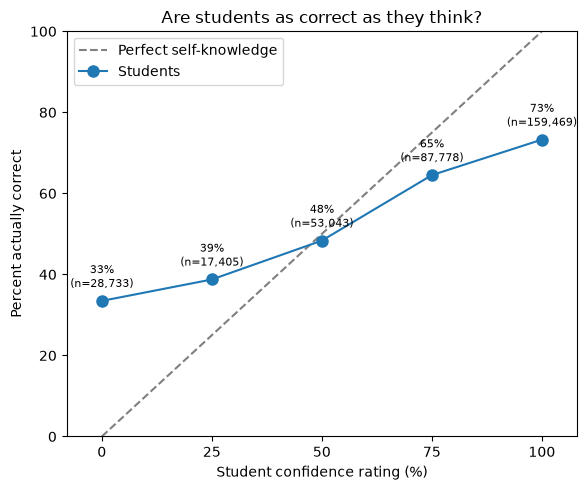

In [6]:
by_conf = df.groupby("Confidence")["IsCorrect"].agg(answers="count", correct="mean")
by_conf["correct"] = by_conf["correct"] * 100
by_conf["gap"] = by_conf["correct"] - by_conf.index

# ---------- Printed output ----------
print("=== How often are students right at each confidence rating? ===")
for rating, row in by_conf.iterrows():
    if row["gap"] > 2:
        verdict = f"underconfident by {row['gap']:.0f} points"
    elif row["gap"] < -2:
        verdict = f"overconfident by {-row['gap']:.0f} points"
    else:
        verdict = "about right"
    print(f"Said {int(rating):>3}% sure: right {row['correct']:4.1f}% of the time "
          f"({int(row['answers']):,} answers) -> {verdict}")

# ---------- Plot ----------
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 100], [0, 100], "--", color="gray", label="Perfect self-knowledge")
ax.plot(by_conf.index, by_conf["correct"], "o-", markersize=8, label="Students")
for rating, row in by_conf.iterrows():
    ax.annotate(f"{row['correct']:.0f}%\n(n={int(row['answers']):,})", (rating, row["correct"]),
                textcoords="offset points", xytext=(0, 10), ha="center", fontsize=8)
ax.set_xlabel("Student confidence rating (%)")
ax.set_ylabel("Percent actually correct")
ax.set_title("Are students as correct as they think?")
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xlim(-8, 108)
ax.set_ylim(0, 100)
ax.legend(loc="upper left")

fig.tight_layout()
fig.savefig(FIG / "confidence_vs_correct.png", dpi=300, bbox_inches="tight")
plt.show()

**Takeaway:** Students are too sure when they feel sure, and not sure enough when they feel unsure. When they say 100%, they are right only 73% of the time. When they say 0%, they are still right 34% of the time. Only 50% is about right. But a higher rating always means more correct answers, so the order is right even if the numbers are wrong.

## 5. Student groups
How much group information do we have, and do the groups perform differently?

### 5a. Group sizes and % correct

=== Gender ===


              students  % of students  answers  % of answers  % correct
gender_group                                                           
Female            1524           31.0   472040          34.1       52.5
Male              1513           30.8   467265          33.8       51.4
Unspecified       1874           38.1   442838          32.0       57.5
Other                7            0.1      584           0.0       72.3

=== Free school meals ===
                      students  % of students  answers  % of answers  % correct
fsm_group                                                                      
Free school meals          601           12.2   197380          14.3       44.4
No free school meals      1512           30.7   510480          36.9       54.6
Unknown                   2805           57.0   674867          48.8       55.8


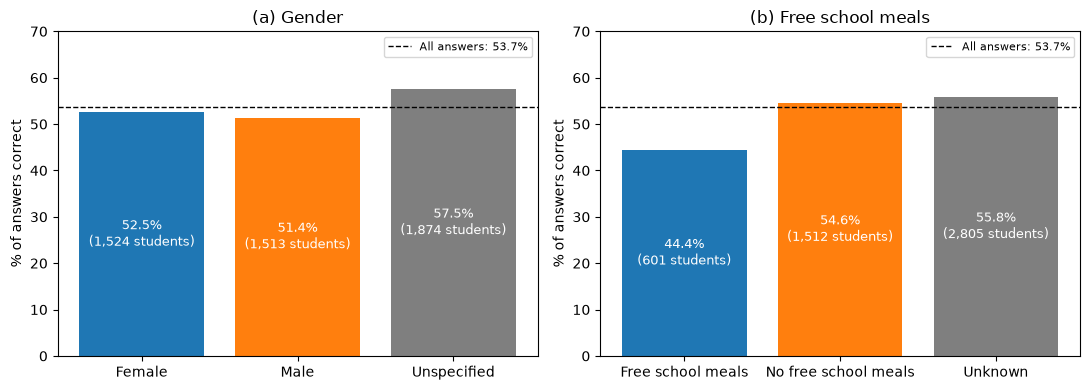

In [7]:
df["gender_group"] = df["Gender"].map({0: "Unspecified", 1: "Female", 2: "Male", 3: "Other"})
df["fsm_group"] = df["PremiumPupil"].map({1.0: "Free school meals", 0.0: "No free school meals"}).fillna("Unknown")

students = df.drop_duplicates("UserId")   # one row per student


def group_summary(col, order):
    """Students, answers and % correct for each group."""
    t = pd.DataFrame({
        "students": students[col].value_counts(),
        "answers": df[col].value_counts(),
        "% correct": df.groupby(col)["IsCorrect"].mean() * 100,
    }).reindex(order)
    t["% of students"] = t["students"] / t["students"].sum() * 100
    t["% of answers"] = t["answers"] / t["answers"].sum() * 100
    return t[["students", "% of students", "answers", "% of answers", "% correct"]].round(1)


# ---------- Printed output ----------
print("=== Gender ===")
gender = group_summary("gender_group", ["Female", "Male", "Unspecified", "Other"])
print(gender.to_string())

print("\n=== Free school meals ===")
fsm = group_summary("fsm_group", ["Free school meals", "No free school meals", "Unknown"])
print(fsm.to_string())

# ---------- Figure ----------
overall = df["IsCorrect"].mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, t, title in [(axes[0], gender.drop("Other"), "(a) Gender"),
                     (axes[1], fsm, "(b) Free school meals")]:
    bars = ax.bar(t.index, t["% correct"], color=["tab:blue", "tab:orange", "tab:gray"])
    ax.bar_label(bars, labels=[f"{p:.1f}%\n({int(s):,} students)" for p, s in zip(t["% correct"], t["students"])],
                 label_type="center", color="white", fontsize=9)
    ax.axhline(overall, color="black", linestyle="--", linewidth=1, label=f"All answers: {overall:.1f}%")
    ax.set_ylim(0, 70)
    ax.set_ylabel("% of answers correct")
    ax.set_title(title)
    ax.legend(loc="upper right", fontsize=8)

fig.tight_layout()
fig.savefig(FIG / "groups.png", dpi=300, bbox_inches="tight")
plt.show()

**Takeaway:** There are about as many female as male students (about 1,500 each), and they do about equally well (52.5% and 51.4% correct). Gender is unknown for 38% of students, and "other" has only 7 students, which is too few to study.

Free-school-meal status is unknown for 57% of students. Students on free school meals get 44.4% right, about 10 points less than other students (54.6%). Later we check if the models work equally well for them.

### 5b. Confidence by group
Are some groups more overconfident than others?

=== Confidence by gender ===
              rated answers  % of answers rated  avg confidence  % correct (rated)  % of ratings = 100  % correct when 100  overconfidence
gender_group                                                                                                                              
Female             118142.0                25.0            70.4               60.0                40.1                72.5            10.4
Male               109729.0                23.5            76.7               62.0                50.7                71.5            14.7
Unspecified        118557.0                26.8            75.0               64.6                47.6                75.6            10.4

=== Confidence by free school meals ===
                      rated answers  % of answers rated  avg confidence  % correct (rated)  % of ratings = 100  % correct when 100  overconfidence
fsm_group                                                                               

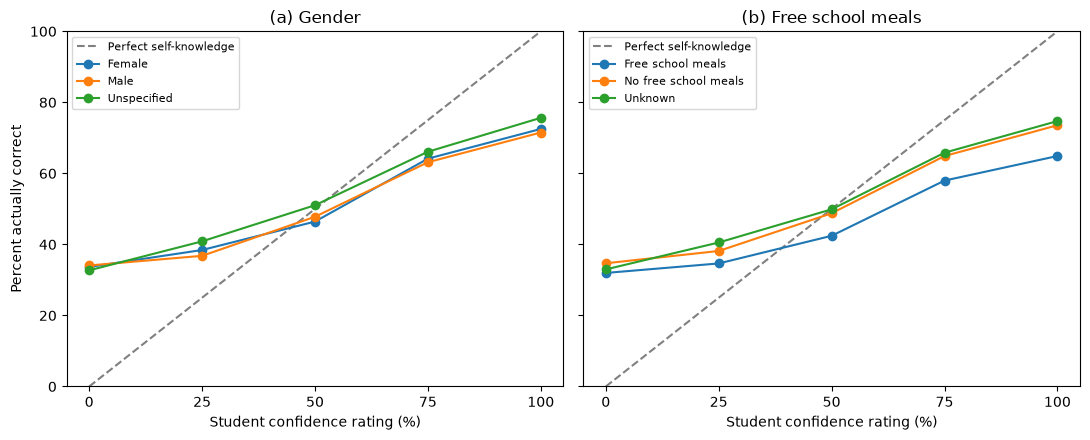

In [8]:
# rebuild `rated` so it has the new group columns from 5a
rated = df[df["Confidence"].notna()]


def confidence_summary(col, order):
    """For each group: how often they rate, how sure they say they are, and how right they really are."""
    g = rated.groupby(col)
    t = pd.DataFrame({
        "rated answers": g.size(),
        "% of answers rated": df.groupby(col)["Confidence"].apply(lambda c: c.notna().mean() * 100),
        "avg confidence": g["Confidence"].mean(),
        "% correct (rated)": g["IsCorrect"].mean() * 100,
        "% of ratings = 100": g["Confidence"].apply(lambda c: (c == 100).mean() * 100),
        "% correct when 100": rated[rated["Confidence"] == 100].groupby(col)["IsCorrect"].mean() * 100,
    }).reindex(order)
    t["overconfidence"] = t["avg confidence"] - t["% correct (rated)"]   # how much they overestimate
    return t.round(1)


# ---------- Printed output ----------
print("=== Confidence by gender ===")
print(confidence_summary("gender_group", ["Female", "Male", "Unspecified"]).to_string())
print("\n=== Confidence by free school meals ===")
print(confidence_summary("fsm_group", ["Free school meals", "No free school meals", "Unknown"]).to_string())

# ---------- Figure ----------
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, col, order, title in [
    (axes[0], "gender_group", ["Female", "Male", "Unspecified"], "(a) Gender"),
    (axes[1], "fsm_group", ["Free school meals", "No free school meals", "Unknown"], "(b) Free school meals"),
]:
    ax.plot([0, 100], [0, 100], "--", color="gray", label="Perfect self-knowledge")
    for group in order:
        by_rating = rated[rated[col] == group].groupby("Confidence")["IsCorrect"].mean() * 100
        ax.plot(by_rating.index, by_rating.values, "o-", label=group)
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.set_xlim(-5, 105)
    ax.set_ylim(0, 100)
    ax.set_xlabel("Student confidence rating (%)")
    ax.set_title(title)
    ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel("Percent actually correct")

fig.tight_layout()
fig.savefig(FIG / "confidence_by_group.png", dpi=300, bbox_inches="tight")
plt.show()

**Takeaway:** All groups are too confident, but some more than others. Boys choose 100% more often than girls (51% vs. 40% of ratings), but they are not right more often, so they overestimate more. At the same rating, boys and girls are right about equally often.

Students on free school meals are the most overconfident. At every rating they are right less often, and when they say 100% they are right only 65% of the time (74% for other students).

## 6. Topics
Which topic level should be the "skill" for our features?

=== Topics at each level ===
       topics  questions per topic (median)  min  max  topics with ≤5 questions  answers per topic (median)
level                                                                                                      
0           1                         948.0  948  948                         0                     1382727
1           3                         295.0  144  509                         0                      416254
2          25                          18.0    2  141                         1                       23980
3          57                          15.0    1   59                        12                       15761

=== Level 1: 3 topics ===
skill_L1
Number                  509
Geometry and Measure    295
Algebra                 144

=== Level 2: 25 topics ===
skill_L2
Fractions                                         141
Negative Numbers                                  116
Factors, Multiples and Primes                     106
Basi

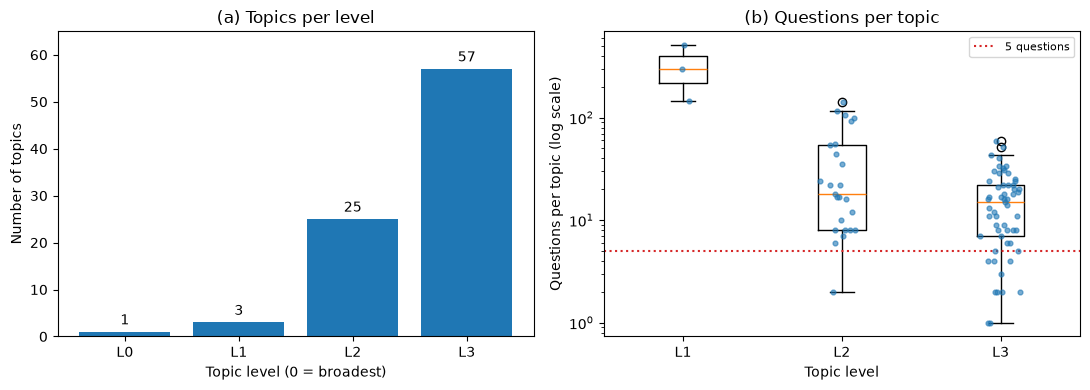

In [9]:
subjects = pd.read_csv("../data/metadata/subject_metadata.csv")
name_of = dict(zip(subjects["SubjectId"], subjects["Name"]))

q = df.drop_duplicates("QuestionId")   # one row per question (948)

# ---------- Summary table ----------
rows = []
per_level = {}
for level in [0, 1, 2, 3]:
    per_topic = q[f"skill_L{level}"].map(name_of).value_counts()   # questions per topic, by name
    per_level[level] = per_topic
    answers_per_topic = df[f"skill_L{level}"].value_counts()
    rows.append({
        "level": level,
        "topics": len(per_topic),
        "questions per topic (median)": per_topic.median(),
        "min": per_topic.min(),
        "max": per_topic.max(),
        "topics with ≤5 questions": (per_topic <= 5).sum(),
        "answers per topic (median)": int(answers_per_topic.median()),
    })
print("=== Topics at each level ===")
print(pd.DataFrame(rows).set_index("level").to_string())

# ---------- Every topic and its number of questions (level 0 is only "Maths") ----------
for level in [1, 2, 3]:
    print(f"\n=== Level {level}: {len(per_level[level])} topics ===")
    print(per_level[level].to_string())

# ---------- Figure ----------
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ax = axes[0]
bars = ax.bar([f"L{l}" for l in per_level], [len(v) for v in per_level.values()], color="tab:blue")
ax.bar_label(bars, padding=3)
ax.set_xlabel("Topic level (0 = broadest)")
ax.set_ylabel("Number of topics")
ax.set_title("(a) Topics per level")
ax.set_ylim(0, 65)

ax = axes[1]
ax.boxplot([per_level[l].values for l in [1, 2, 3]], tick_labels=["L1", "L2", "L3"])
rng = np.random.default_rng(0)
for i, l in enumerate([1, 2, 3], start=1):
    ax.scatter(rng.normal(i, 0.06, len(per_level[l])), per_level[l].values, s=12, alpha=0.6, color="tab:blue", zorder=3)
ax.axhline(5, color="tab:red", linestyle=":", label="5 questions")
ax.set_yscale("log")
ax.set_xlabel("Topic level")
ax.set_ylabel("Questions per topic (log scale)")
ax.set_title("(b) Questions per topic")
ax.legend(fontsize=8, loc="upper right")

fig.tight_layout()
fig.savefig(FIG / "topics.png", dpi=300, bbox_inches="tight")
plt.show()

**Takeaway:** Each question has one topic at each of 4 levels, from very broad (level 0, "Maths") to very specific (level 3). Levels 0 and 1 are too broad to describe a skill. Level 3 is specific, but 12 of its topics have 5 questions or fewer, so students have little or no history on them. Level 2 is in the middle. We build skill features for levels 1–3 and choose the best one later with forward selection.

## 7. Time order
Timestamps only go to the minute. How often does a student answer several questions in the same minute?

=== Answers that share a minute with another answer by the same student ===
Answers in a tie:            940,464 (68.0% of all answers)
Minutes with 2+ answers:     274,353 of 716,616 student-minutes
...all from the same quiz:   96.3%
Answers in a minute of 10+:  14.3%

Typical student (median): 70% of their answers share a minute

Example (student 1):
   UserId  QuestionId  QuizId        DateAnswered  IsCorrect
1       1         202      75 2019-10-11 13:17:00          0
2       1         420      75 2019-10-11 13:17:00          1
5       1         261      75 2019-10-11 13:20:00          0
6       1         503      75 2019-10-11 13:20:00          0
7       1         289      75 2019-10-11 13:21:00          0
8       1         566      75 2019-10-11 13:21:00          1


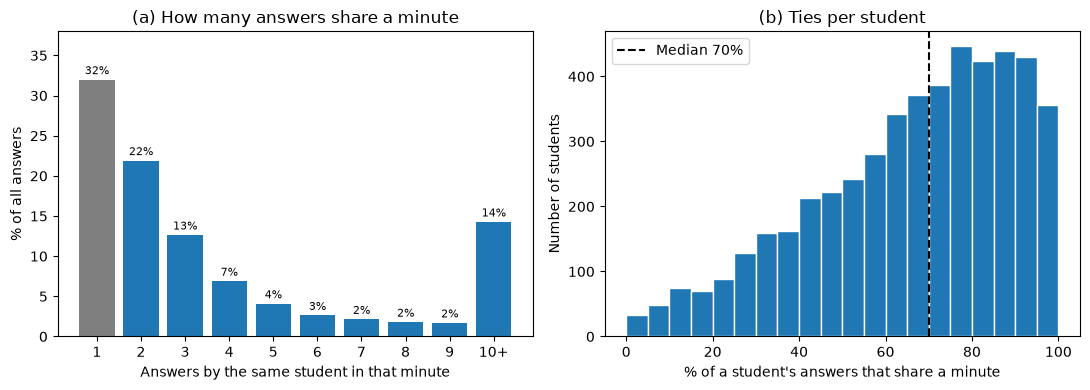

In [10]:
tied = df.duplicated(subset=["UserId", "DateAnswered"], keep=False)
minute_size = df.groupby(["UserId", "DateAnswered"])["AnswerId"].transform("size")   # answers in that student-minute
per_minute = df.groupby(["UserId", "DateAnswered"]).agg(answers=("AnswerId", "size"),
                                                         quizzes=("QuizId", "nunique"))
busy = per_minute[per_minute["answers"] > 1]

# ---------- Printed output ----------
print("=== Answers that share a minute with another answer by the same student ===")
print(f"Answers in a tie:            {tied.sum():,} ({tied.mean() * 100:.1f}% of all answers)")
print(f"Minutes with 2+ answers:     {len(busy):,} of {len(per_minute):,} student-minutes")
print(f"...all from the same quiz:   {(busy['quizzes'] == 1).mean() * 100:.1f}%")
print(f"Answers in a minute of 10+:  {(minute_size >= 10).mean() * 100:.1f}%")

student_tied = tied.groupby(df["UserId"]).mean() * 100
print(f"\nTypical student (median): {student_tied.median():.0f}% of their answers share a minute")

print("\nExample (student 1):")
print(df[tied][["UserId", "QuestionId", "QuizId", "DateAnswered", "IsCorrect"]].head(6).to_string())

# ---------- Figure ----------
share = minute_size.clip(upper=10).value_counts(normalize=True).sort_index() * 100

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ax = axes[0]
labels = [str(int(k)) if k < 10 else "10+" for k in share.index]
colors = ["tab:gray"] + ["tab:blue"] * (len(share) - 1)
bars = ax.bar(labels, share.values, color=colors)
ax.bar_label(bars, fmt="%.0f%%", padding=2, fontsize=8)
ax.set_xlabel("Answers by the same student in that minute")
ax.set_ylabel("% of all answers")
ax.set_title("(a) How many answers share a minute")
ax.set_ylim(0, 38)

ax = axes[1]
ax.hist(student_tied, bins=20, range=(0, 100), edgecolor="white")
ax.axvline(student_tied.median(), color="black", linestyle="--", label=f"Median {student_tied.median():.0f}%")
ax.set_xlabel("% of a student's answers that share a minute")
ax.set_ylabel("Number of students")
ax.set_title("(b) Ties per student")
ax.legend()

fig.tight_layout()
fig.savefig(FIG / "time_ties.png", dpi=300, bbox_inches="tight")
plt.show()

**Takeaway:** Time is only recorded to the minute. 68% of answers share their minute with another answer by the same student, almost always in the same quiz. Sometimes 10 or more answers share one minute, so the time is probably when the quiz was sent, not when each question was answered. We can't know the real order inside a minute, so our features only use answers from earlier minutes.